# How a head is valued: five short lessons

The rule removes a head when the other heads can cover for it. This notebook builds that idea by
**trying numbers**, not by reading formulas. Every formula you have seen (inverse, Hessian, Optimal
Brain Surgeon) turns out to be a fast way to get an answer you can find here by trial.

**How to use it.** In each lesson:
1. Read the question and **write down a guess** before running the cell.
2. Run the cell and compare.
3. Say the takeaway out loud in one sentence.
4. Change one number and run again. That is where most of the learning happens.

About 10 minutes per lesson.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)

## Lesson 1. A head's value: how much worse without it?

Two heads, three tokens. Each head gives one number per token. The model's prediction is

    prediction = w1 * head1 + w2 * head2

and the loss is the sum of squared errors: add up (target − prediction)² over the tokens.

With weights w1 = 2 and w2 = 1 the prediction is perfect. What happens if head 2 is switched off
and head 1 **keeps its weight of 2**?

**Guess first:** is the new loss 0, a little, or a lot?

In [2]:
head1 = np.array([1, 1, 0])
head2 = np.array([1, 0, 1])
y     = np.array([3, 2, 1])              # the target

def loss(prediction):
    return ((y - prediction) ** 2).sum()

print("both heads, weights (2, 1):", loss(2 * head1 + 1 * head2))
print("head 2 off, head 1 keeps 2: ", loss(2 * head1))

both heads, weights (2, 1): 0
head 2 off, head 1 keeps 2:  2


**Takeaway:** switching head 2 off raises the loss from 0 to 2. That 2 is head 2's value *if nobody
adjusts*. This is "ordinary importance" (the lecture calls it Optimal Brain Damage).

**Try:** change w2 to 3 in the first line. Does switching head 2 off now cost more or less?

## Lesson 2. Re-fit: let head 1 pick its best weight

When head 2 is gone, head 1 does not have to keep weight 2. It can pick **whatever weight works
best**. That is all "re-fit" means. Let's just try every weight.

**Guess first:** is the best weight for head 1 still 2, or something else? And is the loss still 2?

In [3]:
for w in np.arange(0, 5.01, 0.5):
    print(f"head 1 weight {w:.1f}  ->  loss {loss(w * head1):.2f}")

head 1 weight 0.0  ->  loss 14.00
head 1 weight 0.5  ->  loss 9.50
head 1 weight 1.0  ->  loss 6.00
head 1 weight 1.5  ->  loss 3.50
head 1 weight 2.0  ->  loss 2.00
head 1 weight 2.5  ->  loss 1.50
head 1 weight 3.0  ->  loss 2.00
head 1 weight 3.5  ->  loss 3.50
head 1 weight 4.0  ->  loss 6.00
head 1 weight 4.5  ->  loss 9.50
head 1 weight 5.0  ->  loss 14.00


The loss falls, bottoms out, and rises again. Let's draw it.

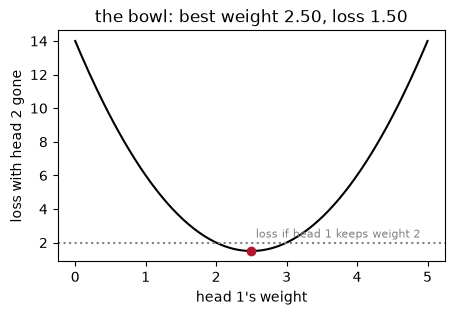

In [4]:
ws = np.linspace(0, 5, 201)
losses = [loss(w * head1) for w in ws]
best = ws[np.argmin(losses)]

plt.figure(figsize=(5, 3))
plt.plot(ws, losses, color="black")
plt.plot(best, min(losses), "o", color="#b2182b")
plt.axhline(2, color="gray", ls=":")
plt.text(4.9, 2.3, "loss if head 1 keeps weight 2", ha="right", color="gray", fontsize=8)
plt.xlabel("head 1's weight"); plt.ylabel("loss with head 2 gone")
plt.title(f"the bowl: best weight {best:.2f}, loss {min(losses):.2f}")
plt.show()

**Takeaway:** the loss is a **bowl**. Re-fitting means finding its bottom: weight 2.5, loss 1.5. So
head 2's value **with re-fit** is 1.5, less than the 2 from lesson 1, because head 1 took over part of
head 2's job by raising its weight.

**The formula is just a shortcut to the bottom of this bowl:**

    best weight = (head1 · y) / (head1 · head1)        (· means multiply entry by entry, then add)

In [5]:
best_w = (head1 @ y) / (head1 @ head1)
print("formula best weight:", best_w, "   loss there:", loss(best_w * head1))

formula best weight: 2.5    loss there: 1.5


**Try:** change y to (3, 2, 5). Guess whether the bottom moves left or right, then run both cells.

## Lesson 3. A copy is worth nothing

Now make head 2 an **exact copy** of head 1, and let the target be head1 + head2.

**Guess first:** with re-fit, what is head 2's value? Without re-fit?

In [6]:
copy = head1.copy()
y_copy = head1 + copy                    # = (2, 2, 0)

def loss_c(prediction):
    return ((y_copy - prediction) ** 2).sum()

print("no re-fit (head 1 keeps weight 1):", loss_c(1 * head1))
best_w = (head1 @ y_copy) / (head1 @ head1)
print("re-fit: head 1's best weight", best_w, "-> loss", loss_c(best_w * head1))

no re-fit (head 1 keeps weight 1): 2
re-fit: head 1's best weight 2.0 -> loss 0.0


**Takeaway:** without re-fit, the copy looks important (value 2). With re-fit, head 1 simply doubles
its weight and covers everything: **value 0**. This is the whole reason the rule re-fits: it removes
copies and keeps heads that do something unique.

## Lesson 4. Overlap is cover

Between "completely different" and "exact copy" there is everything in between. Slide head 2 from
unique (overlap 0) to a copy of head 1 (overlap 1), and each time measure head 2's value with and
without re-fit. The target is always head1 + head2, so both heads have weight 1.

**Guess first:** as the overlap grows, what happens to each value?

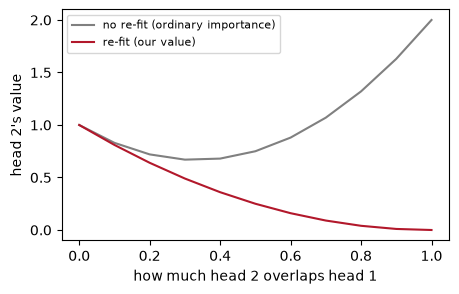

In [7]:
unique = np.array([0, 0, 1])             # shares nothing with head 1
overlaps = np.linspace(0, 1, 11)
no_refit, refit = [], []
for t in overlaps:
    h2 = (1 - t) * unique + t * head1    # t = 0: unique,  t = 1: a copy of head 1
    target = head1 + h2
    no_refit.append(((target - head1) ** 2).sum())                 # head 1 keeps weight 1
    w = (head1 @ target) / (head1 @ head1)                         # head 1 re-fits
    refit.append(((target - w * head1) ** 2).sum())

plt.figure(figsize=(5, 3))
plt.plot(overlaps, no_refit, color="gray", label="no re-fit (ordinary importance)")
plt.plot(overlaps, refit, color="#b2182b", label="re-fit (our value)")
plt.xlabel("how much head 2 overlaps head 1"); plt.ylabel("head 2's value")
plt.legend(fontsize=8); plt.show()

**Takeaway:** the more head 2 overlaps head 1, the more head 1 can cover for it, and the lower its
re-fitted value, down to 0 for a copy. Without re-fitting, the value never falls to 0: it stays
between about 0.7 and 2, and is highest for the copy, because nobody adjusts to cover for it.

This is what the matrix ZᵀZ records: how much every pair of heads overlaps. The rule uses it to know
how much cover each head has.

## Lesson 5. The inverse is a shortcut, not a new idea

With 32 heads, re-fitting once per head by trial would be slow. The inverse of the overlap matrix
gives **every head's re-fitted value at once**. It is not a new idea. It is the same numbers as
lessons 1 to 3, computed faster.

**Guess first:** the shortcut's values for head 1 and head 2. (Hint: head 2's should match lesson 2.)

In [8]:
Z = np.stack([head1, head2], axis=1)     # columns = heads, rows = tokens
A = Z.T @ Z                              # overlap table
W = np.linalg.solve(A, Z.T @ y)          # best weights for both heads together
M = np.linalg.inv(A)

for k in range(2):
    print(f"head {k + 1}: shortcut value W² / M_kk = {W[k] ** 2 / M[k, k]:.2f}")

# check head 1 by trial, like lesson 2: remove head 1, let head 2 re-fit
w2 = (head2 @ y) / (head2 @ head2)
print("head 1 by trial:", loss(w2 * head2))

head 1: shortcut value W² / M_kk = 6.00
head 2: shortcut value W² / M_kk = 1.50
head 1 by trial: 6.0


**Takeaway:** the shortcut gives 6 for head 1 and 1.5 for head 2, exactly what trial gives.

## The named ideas, each in one sentence

Now each formal term attaches to something you have seen:

- **Re-fit / least squares:** finding the bottom of the bowl in lesson 2.
- **Optimal Brain Damage:** the value without re-fit (lesson 1).
- **Optimal Brain Surgeon:** the value with re-fit (lessons 2 and 5).
- **Hessian:** how sharply the bowl curves; for two heads it is the overlap table ZᵀZ, times 2.
- **Taylor series:** predicting the loss from the bowl's bottom and its curvature. Because the loss
  really is a bowl (a parabola), the prediction is exact, which is why our score is exact.
- **Ridge:** with an exact copy the overlap table cannot be inverted (lesson 3's situation), so the
  code adds a tiny number to its diagonal.

## Say it out loud (the committee questions)

1. *How is a head valued?* Remove it, let the other heads re-pick their weights, see how much worse it gets.
2. *Why re-fit?* Otherwise a copy looks important (lesson 3).
3. *Is it exact?* Yes, for the output weights: the loss is a bowl and we find its bottom (lesson 2).
4. *Why OBS, not OBD?* OBD skips the re-fit, so it cannot see overlap (lesson 4).
5. *What is the inverse for?* Speed: every head's value at once, same numbers (lesson 5).

When these feel easy, do the worksheets in `figures/worksheet_*.png` without code, as a final check.